# Pol-ISARSpaceTarget: Larger YOLO-OBB Models on a Colab T4

Purpose:

- Test whether additional detector capacity improves the strongest previous
  Pol-ISARSpaceTarget-1.0 object-detection baseline.
- Keep dataset conversion, training settings, and evaluation protocol fixed.
- Save a clean comparison table for the guide.
- Use a longer epoch setting with checkpoint resume support.

Compared larger models:

1. YOLO11s-OBB
2. YOLO11m-OBB

The completed YOLO11n-OBB result is retained as the fixed reference baseline.

Main input variant:

- `single_vv`, because previous experiments showed it had the strongest mAP.

This notebook deliberately changes only model capacity. Polarimetric fusion
and augmentation ablations should remain separate experiments.



In [1]:
!pip -q install ultralytics pillow pyyaml pandas matplotlib opencv-python



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 3.5 MB/s eta 0:00:00


In [2]:
import json
import os
import re
import shutil
import time
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from ultralytics import YOLO

print("Ultralytics OBB docs: https://docs.ultralytics.com/tasks/obb/")



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics OBB docs: https://docs.ultralytics.com/tasks/obb/


## Runtime Check



In [3]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"GPU memory: {props.total_memory / 1024**3:.1f} GB")
else:
    raise RuntimeError("GPU is not connected. In Colab select Runtime > Change runtime type > T4 GPU.")




PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB


## Paths and Dataset Root



In [4]:
try:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        DRIVE_BASE = Path("/content/drive/MyDrive")
    except Exception as exc:
        print("Mount at /content/drive failed:", exc)
        print("Trying alternate mount point: /content/gdrive")
        drive.mount("/content/gdrive")
        DRIVE_BASE = Path("/content/gdrive/MyDrive")
except Exception as exc:
    print("Drive mount skipped:", exc)
    DRIVE_BASE = Path("/content/drive/MyDrive")

ROOT_CANDIDATES = [
    DRIVE_BASE / "drdo" / "Pol_ISARSpaceTarget1.0",
    DRIVE_BASE / "drdo" / "Pol_ISARSpaceTarget1.0" / "Pol_ISARSpaceTarget1.0",
    DRIVE_BASE / "drdo" / "Pol_ISAR",
    DRIVE_BASE / "drdo" / "Pol_ISAR" / "Pol_ISARSpaceTarget1.0",
    Path("/content/Pol_ISARSpaceTarget1.0"),
    Path("/content/Pol_ISAR"),
    Path("C:/Users/keerthish/Desktop/drdo/Pol_ISARSpaceTarget1.0"),
]


def is_valid_polisar_root(path: Path) -> bool:
    return (path / "ImageSets" / "labelTxt").exists() and (path / "ImageSets" / "images").exists()


DATASET_ROOT = next((p for p in ROOT_CANDIDATES if is_valid_polisar_root(p)), None)
if DATASET_ROOT is None:
    print("Could not find dataset in default locations. Searching under Drive drdo folder...")
    search_roots = [DRIVE_BASE / "drdo", Path("/content")]
    found = []
    for root in search_roots:
        if root.exists():
            found.extend([p for p in root.rglob("ImageSets") if (p / "labelTxt").exists() and (p / "images").exists()])
    if found:
        DATASET_ROOT = found[0].parent
    else:
        raise FileNotFoundError(
            "Could not locate Pol-ISAR dataset root. Expected a folder containing ImageSets/labelTxt and ImageSets/images."
        )
print("DATASET_ROOT:", DATASET_ROOT)

LABELTXT_DIR = DATASET_ROOT / "ImageSets" / "labelTxt"
DAT_DIR = DATASET_ROOT / "ImageSets" / "images"
TIFF_DIR = DATASET_ROOT / "TIFFImages" / "AmplitudeImages"

assert LABELTXT_DIR.exists(), f"Missing labels: {LABELTXT_DIR}"
assert DAT_DIR.exists(), f"Missing complex dat files: {DAT_DIR}"

OUT_ROOT = Path("/content/polisar_obb_yolo")
DRIVE_OUT = DRIVE_BASE / "drdo" / "polisar_yolo_obb_larger_models"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_OUT.mkdir(parents=True, exist_ok=True)




Mounted at /content/drive
DATASET_ROOT: /content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0


## Label Reader and Class Summary



In [5]:
def read_dota_label_file(path: Path) -> List[Tuple[List[float], str, int]]:
    rows = []
    if not path.exists() or not path.read_text().strip():
        return rows
    for line in path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 10:
            continue
        coords = [float(x) for x in parts[:8]]
        cls_name = parts[8]
        difficult = int(float(parts[9]))
        rows.append((coords, cls_name, difficult))
    return rows


class_names = sorted(
    {
        cls
        for split in ["train", "valid", "test"]
        for txt in (LABELTXT_DIR / split).glob("*.txt")
        for _, cls, _ in read_dota_label_file(txt)
    }
)
class_to_id = {name: idx for idx, name in enumerate(class_names)}
print("Class map:", class_to_id)

split_summary = []
for split in ["train", "valid", "test"]:
    txt_files = sorted((LABELTXT_DIR / split).glob("*.txt"))
    obj_count = sum(len(read_dota_label_file(p)) for p in txt_files)
    split_summary.append({"split": split, "images": len(txt_files), "objects": obj_count})
split_summary_df = pd.DataFrame(split_summary)
display(split_summary_df)
split_summary_df.to_csv(DRIVE_OUT / "dataset_split_summary.csv", index=False)
(DRIVE_OUT / "obb_class_names.json").write_text(json.dumps(class_to_id, indent=2))




Class map: {'cuboid_body': 0, 'optical_lens': 1, 'panel_antenna': 2, 'parabolic_antenna': 3, 'plate_body': 4, 'plate_fitting': 5, 'polygon_body': 6, 'rod_fitting': 7, 'solar_array': 8}


,split,images,objects
0,train,1314,13289
1,valid,162,1613
2,test,174,1723


193

## Image Builders

Only the strongest previous input, `single_vv`, is built. This keeps the
experiment focused on detector size and avoids rebuilding unused variants.



In [6]:
POL_SUFFIXES = ["HH", "HV", "VH", "VV"]


def robust_uint8(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    x = np.log1p(np.maximum(x, 0.0))
    lo, hi = np.percentile(x, [1, 99])
    if hi <= lo:
        hi = lo + 1e-6
    x = np.clip((x - lo) / (hi - lo), 0, 1)
    return (255 * x).astype(np.uint8)


def base_name_candidates(base_name: str) -> List[str]:
    cleaned = re.sub(r"\s+\(\d+\)$", "", base_name)
    return [base_name, cleaned] if cleaned != base_name else [base_name]


def find_first_existing(paths: Sequence[Path]) -> Path | None:
    for path in paths:
        if path.exists():
            return path
    return None


def read_complex_dat(path: Path, shape: Tuple[int, int] = (256, 256)) -> np.ndarray:
    raw = np.fromfile(path, dtype=np.float32)
    real = raw[0::2].reshape(shape)
    imag = raw[1::2].reshape(shape)
    return real + 1j * imag


def find_dat(base_name: str, pol: str, split: str) -> Path:
    path = find_first_existing([DAT_DIR / split / f"{candidate}_{pol}.dat" for candidate in base_name_candidates(base_name)])
    if path is None:
        raise FileNotFoundError(f"No {pol}.dat found for {base_name} in split {split}")
    return path


def build_single_vv(base_name: str, split: str) -> np.ndarray:
    tiff_path = find_first_existing([TIFF_DIR / f"{candidate}_VV.tiff" for candidate in base_name_candidates(base_name)])
    if tiff_path is not None:
        img = np.array(Image.open(tiff_path).convert("L"))
        return np.stack([img, img, img], axis=-1)
    vv = read_complex_dat(find_dat(base_name, "VV", split))
    img = robust_uint8(np.abs(vv))
    return np.stack([img, img, img], axis=-1)


def build_pauli_fusion(base_name: str, split: str) -> np.ndarray:
    c = {pol: read_complex_dat(find_dat(base_name, pol, split)) for pol in POL_SUFFIXES}
    hh, hv, vh, vv = c["HH"], c["HV"], c["VH"], c["VV"]
    r = robust_uint8(np.abs(hh - vv))
    g = robust_uint8(np.abs(hv + vh))
    b = robust_uint8(np.abs(hh + vv))
    return np.stack([r, g, b], axis=-1)




## Convert DOTA-Style OBB Labels to Ultralytics YOLO-OBB Format

Existing labels:

`x1 y1 x2 y2 x3 y3 x4 y4 class difficult`

Ultralytics OBB labels:

`class x1 y1 x2 y2 x3 y3 x4 y4`

with normalized corner coordinates in `[0, 1]`.



In [7]:
def convert_label_to_yolo_obb(src_txt: Path, dst_txt: Path, width: int = 256, height: int = 256) -> int:
    out_lines = []
    for coords, cls_name, difficult in read_dota_label_file(src_txt):
        if difficult == 1:
            continue
        cls_id = class_to_id[cls_name]
        norm = []
        for idx, value in enumerate(coords):
            norm.append(value / width if idx % 2 == 0 else value / height)
        norm = [min(max(v, 0.0), 1.0) for v in norm]
        out_lines.append(" ".join([str(cls_id)] + [f"{v:.6f}" for v in norm]))
    dst_txt.parent.mkdir(parents=True, exist_ok=True)
    dst_txt.write_text("\n".join(out_lines) + ("\n" if out_lines else ""))
    return len(out_lines)


def write_data_yaml(out_dir: Path) -> Path:
    data_yaml = {
        "path": str(out_dir),
        "train": "images/train",
        "val": "images/valid",
        "test": "images/test",
        "names": {idx: name for idx, name in enumerate(class_names)},
    }
    yaml_path = out_dir / "data.yaml"
    yaml_path.write_text(yaml.safe_dump(data_yaml, sort_keys=False))
    return yaml_path


def yolo_dataset_is_complete(out_dir: Path) -> bool:
    yaml_path = out_dir / "data.yaml"
    return (
        yaml_path.exists()
        and (out_dir / "images" / "train").exists()
        and any((out_dir / "images" / "train").glob("*.png"))
        and (out_dir / "labels" / "train").exists()
        and any((out_dir / "labels" / "train").glob("*.txt"))
    )


def build_yolo_dataset(variant: str, max_per_split: int | None = None, force_rebuild: bool = False) -> Path:
    out_dir = OUT_ROOT / variant
    if yolo_dataset_is_complete(out_dir) and not force_rebuild:
        print("Using existing dataset:", out_dir)
        return out_dir / "data.yaml"

    if out_dir.exists():
        shutil.rmtree(out_dir)
    for split in ["train", "valid", "test"]:
        (out_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (out_dir / "labels" / split).mkdir(parents=True, exist_ok=True)
        txt_files = sorted((LABELTXT_DIR / split).glob("*.txt"))
        if max_per_split is not None:
            txt_files = txt_files[:max_per_split]

        for i, txt in enumerate(txt_files, start=1):
            base = txt.stem
            if variant == "single_vv":
                img = build_single_vv(base, split)
            elif variant == "pauli_fusion":
                img = build_pauli_fusion(base, split)
            else:
                raise ValueError(f"Cannot rebuild unknown variant: {variant}")

            cv2.imwrite(str(out_dir / "images" / split / f"{base}.png"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            convert_label_to_yolo_obb(txt, out_dir / "labels" / split / f"{base}.txt")
            if i % 100 == 0:
                print(variant, split, i, "/", len(txt_files))

    yaml_path = write_data_yaml(out_dir)
    print("Prepared:", out_dir)
    return yaml_path




## Build or Reuse Datasets



In [8]:
MAX_PER_SPLIT = None
FORCE_REBUILD_DATASETS = False

dataset_yamls = {
    "single_vv": build_yolo_dataset("single_vv", max_per_split=MAX_PER_SPLIT, force_rebuild=FORCE_REBUILD_DATASETS),
}

print(dataset_yamls)




single_vv train 100 / 1314
single_vv train 200 / 1314
single_vv train 300 / 1314
single_vv train 400 / 1314
single_vv train 500 / 1314
single_vv train 600 / 1314
single_vv train 700 / 1314
single_vv train 800 / 1314
single_vv train 900 / 1314
single_vv train 1000 / 1314
single_vv train 1100 / 1314
single_vv train 1200 / 1314
single_vv train 1300 / 1314
single_vv valid 100 / 162
single_vv test 100 / 174
Prepared: /content/polisar_obb_yolo/single_vv
{'single_vv': PosixPath('/content/polisar_obb_yolo/single_vv/data.yaml')}


## OBB Method List

Official Ultralytics OBB models use the `-obb.pt` suffix and are pretrained on
DOTA-style oriented boxes. If one model is unavailable in your installed
version, this notebook logs the failure and continues with the rest.



In [9]:
OBB_METHODS = [
    {"method": "YOLO11s-OBB", "weights": "yolo11s-obb.pt", "batch": 8},
    {"method": "YOLO11m-OBB", "weights": "yolo11m-obb.pt", "batch": 8},
]

# Main comparison: compare OBB methods on strongest previous input.
INPUT_VARIANTS_TO_RUN = ["single_vv"]

# Optional: uncomment to run the full grid. This takes longer.
# INPUT_VARIANTS_TO_RUN = ["single_vv", "pauli_fusion", "learned_fusion"]

EPOCHS = 100
IMGSZ = 256
PATIENCE = 100
SAVE_PERIOD = 1
SEED = 42

print("Methods:", OBB_METHODS)
print("Input variants:", INPUT_VARIANTS_TO_RUN)
print(f"Training setting: max epochs={EPOCHS}, patience={PATIENCE}, save_period={SAVE_PERIOD}, seed={SEED}")




Methods: [{'method': 'YOLO11s-OBB', 'weights': 'yolo11s-obb.pt', 'batch': 8}, {'method': 'YOLO11m-OBB', 'weights': 'yolo11m-obb.pt', 'batch': 8}]
Input variants: ['single_vv']
Training setting: max epochs=100, patience=100, save_period=1, seed=42


## Train and Evaluate One Method



In [10]:
def metric_value(metrics, *names):
    for name in names:
        obj = metrics
        ok = True
        for part in name.split("."):
            if hasattr(obj, part):
                obj = getattr(obj, part)
            else:
                ok = False
                break
        if ok:
            try:
                return float(obj)
            except Exception:
                pass
    return None


def train_eval_obb(method_name: str, weights: str, batch: int, variant: str, yaml_path: Path) -> Dict:
    run_name = f"{method_name}_{variant}".replace("/", "_").replace(" ", "_")
    run_dir = DRIVE_OUT / "runs_obb_methods" / run_name
    last_ckpt = run_dir / "weights" / "last.pt"
    best_ckpt = run_dir / "weights" / "best.pt"
    completed_flag = run_dir / "training_complete.txt"
    started = time.time()
    row = {
        "method": method_name,
        "weights": weights,
        "input_variant": variant,
        "epochs": EPOCHS,
        "imgsz": IMGSZ,
        "batch": batch,
        "status": "started",
        "run_name": run_name,
    }
    try:
        if completed_flag.exists() and best_ckpt.exists():
            print(f"Training already complete for {run_name}; evaluating saved best checkpoint.")
            model = YOLO(str(best_ckpt))
        elif last_ckpt.exists():
            print(f"Resuming {run_name} from {last_ckpt}")
            model = YOLO(str(last_ckpt))
            model.train(resume=True)
            completed_flag.write_text("Training completed successfully.\n")
        else:
            model = YOLO(weights)
            model.train(
                data=str(yaml_path),
                task="obb",
                epochs=EPOCHS,
                imgsz=IMGSZ,
                batch=batch,
                project=str(DRIVE_OUT / "runs_obb_methods"),
                name=run_name,
                exist_ok=True,
                patience=PATIENCE,
                save=True,
                save_period=SAVE_PERIOD,
                plots=True,
                cache=False,
                workers=2,
                amp=True,
                seed=SEED,
                deterministic=True,
                degrees=0.0,
                translate=0.1,
                scale=0.5,
                fliplr=0.5,
                flipud=0.0,
                mosaic=1.0,
                mixup=0.0,
                close_mosaic=10,
                device=DEVICE,
            )
            completed_flag.write_text("Training completed successfully.\n")
        eval_ckpt = best_ckpt if best_ckpt.exists() else last_ckpt
        eval_model = YOLO(str(eval_ckpt)) if eval_ckpt.exists() else model
        metrics = eval_model.val(data=str(yaml_path), split="test", task="obb", imgsz=IMGSZ, plots=True)
        elapsed = time.time() - started
        row.update(
            {
                "status": "ok",
                "test_precision": metric_value(metrics, "box.mp"),
                "test_recall": metric_value(metrics, "box.mr"),
                "test_mAP50": metric_value(metrics, "box.map50"),
                "test_mAP50_95": metric_value(metrics, "box.map"),
                "elapsed_min": elapsed / 60,
                "run_dir": str(run_dir),
                "best_checkpoint": str(best_ckpt),
                "last_checkpoint": str(last_ckpt),
            }
        )
    except Exception as exc:
        row.update({"status": "failed", "error": repr(exc), "elapsed_min": (time.time() - started) / 60})
        print("FAILED:", method_name, variant, exc)
    return row




## Run Comparison

This may take several hours for 100 epochs.

Runtime-disconnect handling:

- Checkpoints are saved every epoch in Google Drive.
- If Colab disconnects, reconnect GPU and rerun the notebook.
- The training function checks for `weights/last.pt` and resumes automatically.
- Keep `INPUT_VARIANTS_TO_RUN = ["single_vv"]` first, because it gave the best
  previous performance and keeps runtime manageable.

For a quick smoke test, set `EPOCHS = 2` and `MAX_PER_SPLIT = 50`, then restart
runtime and rerun from the top.



In [11]:
results = []
for variant in INPUT_VARIANTS_TO_RUN:
    if variant not in dataset_yamls:
        print("Skipping missing variant:", variant)
        continue
    for method in OBB_METHODS:
        row = train_eval_obb(
            method["method"], method["weights"], method["batch"], variant, dataset_yamls[variant]
        )
        results.append(row)
        pd.DataFrame(results).to_csv(DRIVE_OUT / "obb_method_comparison_live.csv", index=False)
        print(json.dumps(row, indent=2))

results_df = pd.DataFrame(results)
display(results_df)
results_df.to_csv(DRIVE_OUT / "obb_method_comparison_final.csv", index=False)
(DRIVE_OUT / "obb_method_comparison_final.json").write_text(json.dumps(results, indent=2))




Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/polisar_obb_yolo/single_vv/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11s-OBB_single_vv, nbs=

,method,weights,input_variant,epochs,imgsz,batch,status,run_name,test_precision,test_recall,test_mAP50,test_mAP50_95,elapsed_min,run_dir,best_checkpoint,last_checkpoint
0,YOLO11s-OBB,yolo11s-obb.pt,single_vv,100,256,8,ok,YOLO11s-OBB_single_vv,0.881305,0.825588,0.852763,0.628999,62.762175,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...
1,YOLO11m-OBB,yolo11m-obb.pt,single_vv,100,256,8,ok,YOLO11m-OBB_single_vv,0.892630,0.839673,0.870462,0.652411,82.427957,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...,/content/drive/MyDrive/drdo/polisar_yolo_obb_l...


1626

## Plot Comparison



,method,input_variant,test_precision,test_recall,test_mAP50,test_mAP50_95,elapsed_min
1,YOLO11m-OBB,single_vv,0.892630,0.839673,0.870462,0.652411,82.427957
0,YOLO11s-OBB,single_vv,0.881305,0.825588,0.852763,0.628999,62.762175


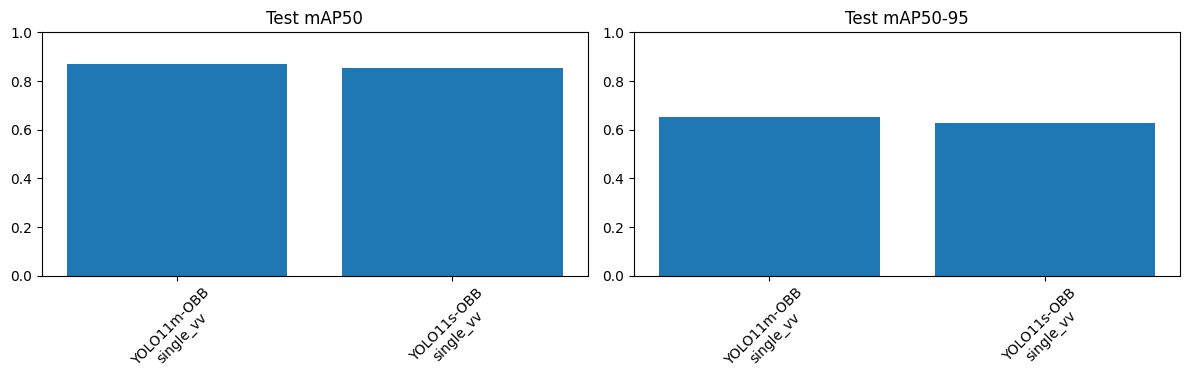

In [12]:
ok_df = results_df[results_df["status"] == "ok"].copy()
if len(ok_df):
    ok_df = ok_df.sort_values("test_mAP50_95", ascending=False)
    display(ok_df[["method", "input_variant", "test_precision", "test_recall", "test_mAP50", "test_mAP50_95", "elapsed_min"]])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(ok_df["method"] + "\n" + ok_df["input_variant"], ok_df["test_mAP50"])
    axes[0].set_title("Test mAP50")
    axes[0].tick_params(axis="x", labelrotation=45)
    axes[0].set_ylim(0, 1)

    axes[1].bar(ok_df["method"] + "\n" + ok_df["input_variant"], ok_df["test_mAP50_95"])
    axes[1].set_title("Test mAP50-95")
    axes[1].tick_params(axis="x", labelrotation=45)
    axes[1].set_ylim(0, 1)

    fig.tight_layout()
    fig.savefig(DRIVE_OUT / "obb_method_comparison_plot.png", dpi=160)
    plt.show()
else:
    print("No completed runs to plot yet.")




## Baseline Reference From Earlier Experiments



In [13]:
reference = pd.DataFrame(
    [
        {
            "method": "YOLO11n-OBB",
            "input_variant": "single_vv",
            "test_precision": 0.804,
            "test_recall": 0.819,
            "test_mAP50": 0.821,
            "test_mAP50_95": 0.582,
            "source": "previous completed notebook",
        },
        {
            "method": "YOLO11n-OBB",
            "input_variant": "pauli_fusion",
            "test_precision": 0.828,
            "test_recall": 0.739,
            "test_mAP50": 0.783,
            "test_mAP50_95": 0.573,
            "source": "previous completed notebook",
        },
        {
            "method": "YOLO11n-OBB",
            "input_variant": "learned_fusion",
            "test_precision": 0.770,
            "test_recall": 0.683,
            "test_mAP50": 0.743,
            "test_mAP50_95": 0.518,
            "source": "previous completed notebook",
        },
    ]
)
display(reference)
reference.to_csv(DRIVE_OUT / "previous_obb_reference_results.csv", index=False)




,method,input_variant,test_precision,test_recall,test_mAP50,test_mAP50_95,source
0,YOLO11n-OBB,single_vv,0.804,0.819,0.821,0.582,previous completed notebook
1,YOLO11n-OBB,pauli_fusion,0.828,0.739,0.783,0.573,previous completed notebook
2,YOLO11n-OBB,learned_fusion,0.770,0.683,0.743,0.518,previous completed notebook


## Final Model-Scale Table and Training Curves

The earlier `n` result is a historical reference. The `s` and `m` rows are
directly comparable to each other because this notebook uses one fixed setup.



,method,input_variant,test_precision,test_recall,test_mAP50,test_mAP50_95,comparison_type
0,YOLO11n-OBB,single_vv,0.804000,0.819000,0.821000,0.582000,earlier baseline
1,YOLO11m-OBB,single_vv,0.892630,0.839673,0.870462,0.652411,controlled larger-model run
2,YOLO11s-OBB,single_vv,0.881305,0.825588,0.852763,0.628999,controlled larger-model run


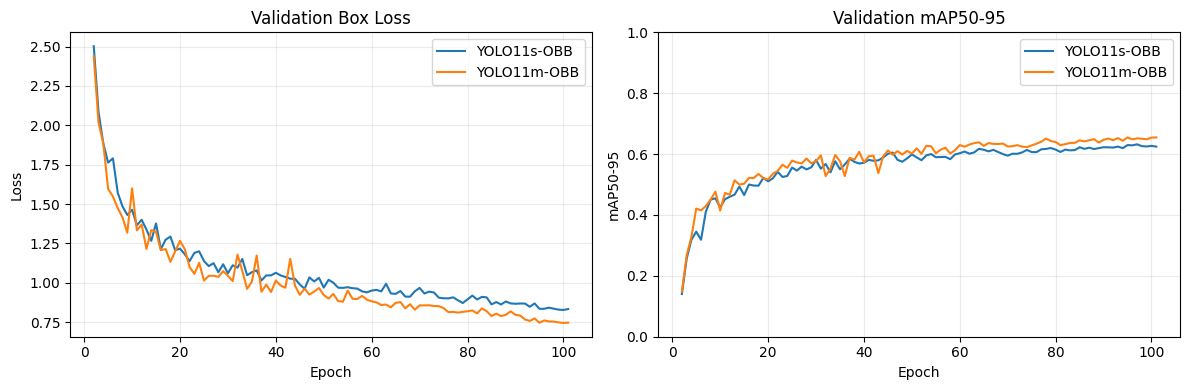

In [14]:
new_cols = [
    "method",
    "input_variant",
    "test_precision",
    "test_recall",
    "test_mAP50",
    "test_mAP50_95",
]
historical = reference[new_cols].copy()
historical["comparison_type"] = "earlier baseline"

current = ok_df[new_cols].copy() if len(ok_df) else pd.DataFrame(columns=new_cols)
current["comparison_type"] = "controlled larger-model run"
model_scale_comparison = pd.concat([historical.iloc[[0]], current], ignore_index=True)
display(model_scale_comparison)
model_scale_comparison.to_csv(DRIVE_OUT / "model_scale_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plotted = False
for method in OBB_METHODS:
    run_name = f"{method['method']}_single_vv".replace("/", "_").replace(" ", "_")
    csv_path = DRIVE_OUT / "runs_obb_methods" / run_name / "results.csv"
    if not csv_path.exists():
        continue
    history = pd.read_csv(csv_path)
    history.columns = [c.strip() for c in history.columns]
    epoch = history["epoch"] + 1
    loss_col = next((c for c in history.columns if c.startswith("val/") and "box_loss" in c), None)
    map_col = next((c for c in history.columns if "metrics/mAP50-95" in c), None)
    if loss_col:
        axes[0].plot(epoch, history[loss_col], label=method["method"])
        plotted = True
    if map_col:
        axes[1].plot(epoch, history[map_col], label=method["method"])

if plotted:
    axes[0].set(title="Validation Box Loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation mAP50-95", xlabel="Epoch", ylabel="mAP50-95", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.tight_layout()
    fig.savefig(DRIVE_OUT / "larger_model_training_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    plt.close(fig)
    print("Training curves will appear after at least one model finishes training.")
